<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and fixture provenance](README.md)

# 01 · Why does a funding rate need its settlement interval?

A per-settlement funding rate has a time denominator. Applying one fixed interval to a series whose cadence changes can distort the comparison even when every rate is copied correctly. We will inspect settlement spacing, reproduce the worker's simple annualization in SQL, and measure the discrepancy introduced by a fixed interval assumption.

**All plotted values are synthetic test data**, generated by the real worker's built-in fixture exchange. The exchange names are fixture identifiers, not evidence of historical exchange behavior. No real trades, balances or orders are involved. This is a unit-and-timing investigation, not a yield estimate or trading recommendation.

## Choose the deliberately fixed assumption

`ASSUMED_HOURS` is the constant funding interval used by our comparison formula: either 8 or 4 hours. The worker's own inferred interval stays unchanged. The experiment changes only **8 → 4 hours**; predict that the discrepancy will move from the four-hour segment to the eight-hour segment.

The source window is fixed and half-open: **2024-01-26 00:00 UTC ≤ settlement < 2024-02-05 00:00 UTC**. Restart the kernel and Run All after editing. The fixture is explicitly selected on every run; it is never a fallback for failed live requests.

In [1]:
ASSUMED_HOURS = 8  # Either 8 or 4 hours per settlement; experiment: 4

In [2]:
import hashlib
import json
import os
from pathlib import Path
from datetime import datetime, timezone

import haybarn
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

assert type(ASSUMED_HOURS) is int and ASSUMED_HOURS in (4,8)
fixture=Path("fixtures.json").resolve()
assert fixture.is_file(), "Run from this notebooks directory with fixtures.json beside the notebook."
fixture_hash=hashlib.sha256(fixture.read_bytes()).hexdigest()
os.environ["VGI_CCXT_FIXTURES"]=str(fixture)
os.environ.pop("VGI_BEARER_TOKENS",None)
os.environ["PLOOMBER_STATS_ENABLED"]="false"
sns.set_theme(style="whitegrid",context="notebook")
plt.rcParams.update({"figure.dpi":125,"text.parse_math":False,"axes.spines.top":False,"axes.spines.right":False})
def prose(text):display(Markdown(text))
def finish(fig):
    fig.text(.01,.01,"Source: built-in CCXT worker fixture · synthetic settlements · 2024-01-26 to 2024-02-05 UTC (end excluded)",fontsize=8,color="#555555")
    fig.tight_layout(rect=(0,.05,1,.96));plt.show()
con=haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-ccxt/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-ccxt/notebooks/pyproject.toml.

## Attach the pinned worker, then check capability

The literal uvx command downloads the Git-tagged worker into uv's cache. Its CCXT, SDK and RPC versions match the tested release environment; the surrounding worker checkout is unnecessary. `fixtures.json` is an unchanged copy of the repository's shipped test fixture.

Capability is a prerequisite, not a promise of data in our window. Here we check both before treating an empty result as a measured zero.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'ccxt' AS ccxt (
    TYPE vgi,
    LOCATION 'uvx --from git+https://github.com/Query-farm/vgi-ccxt@v0.1.0 --with ccxt==4.5.92 --with vgi-python==0.51.1 --with vgi-rpc==0.53.1 vgi-ccxt-worker'
);

,Success


In [4]:
%%sql
CREATE TABLE capabilities AS
SELECT exchange,supported,status FROM ccxt.main.has(['binance','okx','kraken'])
WHERE method='fetchFundingRateHistory';

,Count


## Materialize one bounded scan per supported fixture

Both supported venues receive explicit start and end timestamps. `max_rows := 1000` is a protective output cap; the time interval is what bounds the requested history. The Binance fixture limits funding pages to 30 rows, so this window exercises cursor continuation. The OKX fixture begins later than this window and should be retained as empty, not filled with zero funding.

We do not call the unsupported Kraken history method. A capability failure and an empty supported scan are different outcomes. These are synthetic settlement times; the wall clock recorded below is the execution time, not a source publication timestamp.

In [5]:
started_at=datetime.now(timezone.utc).isoformat()

In [6]:
%%sql
CREATE TABLE funding_source AS
SELECT * FROM ccxt.main.funding_rates('binance','BTC/USDT:USDT',
    start_date := TIMESTAMP '2024-01-26 00:00:00',end_date := TIMESTAMP '2024-02-05 00:00:00',max_rows := 1000)
UNION ALL
SELECT * FROM ccxt.main.funding_rates('okx','BTC/USDT:USDT',
    start_date := TIMESTAMP '2024-01-26 00:00:00',end_date := TIMESTAMP '2024-02-05 00:00:00',max_rows := 1000);

,Count


In [7]:
completed_at=datetime.now(timezone.utc).isoformat()

In [8]:
%%sql availability <<
SELECT c.exchange,c.supported,c.status,count(f.ts) AS settlements,
       min(f.ts) AS first_settlement_utc,max(f.ts) AS last_settlement_utc,
       CASE WHEN NOT c.supported THEN 'unsupported; not requested'
            WHEN count(f.ts)=0 THEN 'supported; empty window' ELSE 'observed fixture rows' END AS availability
FROM capabilities c LEFT JOIN funding_source f USING(exchange)
GROUP BY c.exchange,c.supported,c.status ORDER BY c.exchange;

In [9]:
display(availability)
prose(f"Fixture SHA-256: `{fixture_hash}`. Execution UTC: **{started_at} → {completed_at}**. "
      f"Of {len(availability)} fixture venues checked, **{int(availability.supported.sum())}** support funding history; "
      f"**{int((availability.settlements>0).sum())}** contributes observations in this window. Empty and unsupported rows remain labeled separately.")

,exchange,supported,status,settlements,first_settlement_utc,last_settlement_utc,availability
0,binance,True,native,42,2024-01-26,2024-02-04 20:00:00,observed fixture rows
1,kraken,False,unsupported,0,NaT,NaT,unsupported; not requested
2,okx,True,native,0,NaT,NaT,supported; empty window


Fixture SHA-256: `6d4af927d0c7c98dcc51943d0ee54890e64269b2f5c5161e942911fdb387f4ed`. Execution UTC: **2026-11-14T05:55:13.944640+00:00 → 2026-11-14T05:55:15.345654+00:00**. Of 3 fixture venues checked, **2** support funding history; **1** contributes observations in this window. Empty and unsupported rows remain labeled separately.

## Put the rate and its time denominator beside each other

The worker infers interval length from adjacent settlements. For the first row it can use the following gap, and for a lone row it can consult the declared current interval. Nonstandard gaps may retain the last known interval. This heuristic is useful but is not proof of complete settlement history: a missing row that produces another standard gap can be ambiguous.

Our fixture has a known complete schedule. In this window, compare adjacent gaps with the inferred intervals for every row after the first. The settlement at **2024-02-01 00:00 UTC** still closes an eight-hour interval; the following settlement at 04:00 closes the first four-hour interval. The chart marks the first row the worker labels with the new interval.

In [10]:
%%sql settlements <<
SELECT *,epoch(ts-lag(ts) OVER (PARTITION BY exchange,symbol ORDER BY ts))/3600.0 AS preceding_gap_hours,
       funding_rate*10000 AS rate_bps
FROM funding_source ORDER BY exchange,symbol,ts;

,exchange,ts,rate_bps,interval_hours,preceding_gap_hours
0,binance,2024-01-26 00:00:00,-1.0,8.0,NaN
1,binance,2024-01-26 08:00:00,0.0,8.0,8.0
2,binance,2024-01-26 16:00:00,1.0,8.0,8.0
3,binance,2024-01-27 00:00:00,2.0,8.0,8.0
4,binance,2024-01-27 08:00:00,3.0,8.0,8.0
5,binance,2024-01-27 16:00:00,4.0,8.0,8.0
6,binance,2024-01-28 00:00:00,-4.0,8.0,8.0
7,binance,2024-01-28 08:00:00,-3.0,8.0,8.0


The scan returned **42 unique settlements**, spanning **2024-01-26 00:00:00 → 2024-02-04 20:00:00 UTC**. The observed interval values are **4, 8 hours**; all **41** available preceding gaps match. Source fingerprint: `b58bb6d1313aa652ad41f3f593f39581865d33d3c825759b9c887d21471bde1d`.

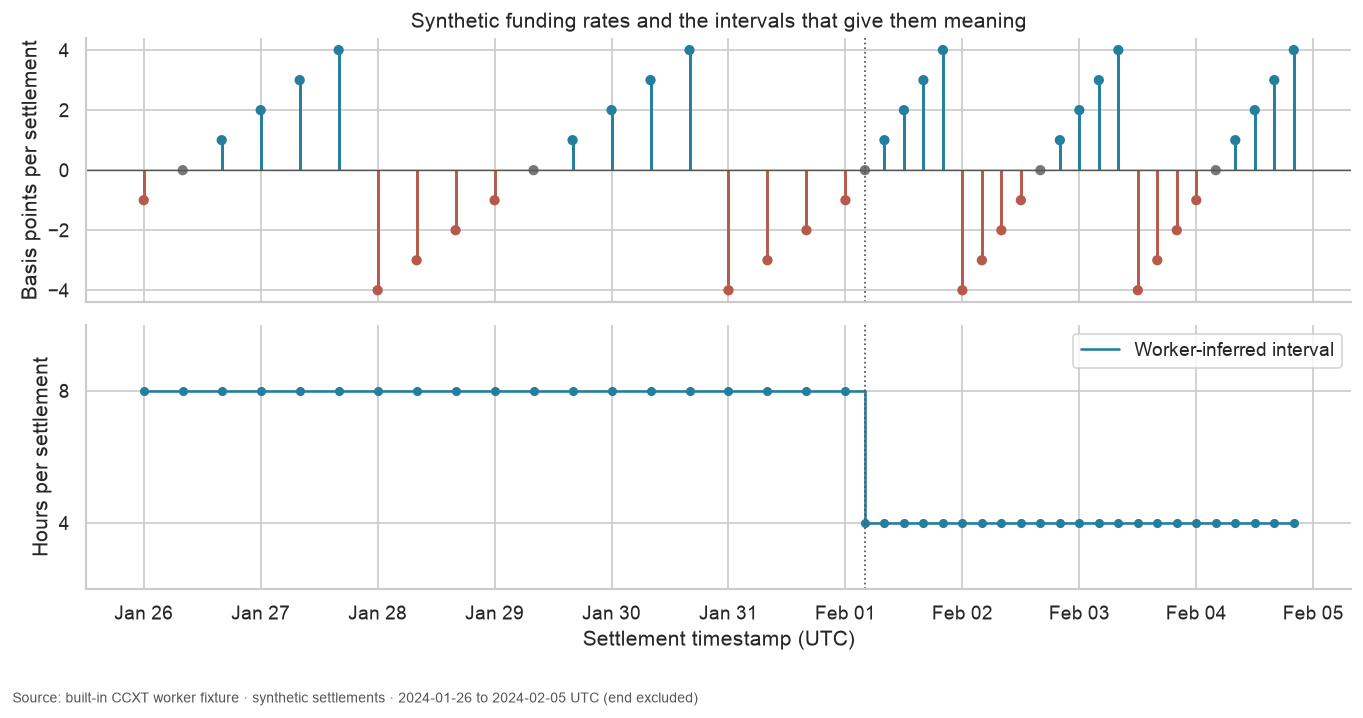

In [11]:
display(settlements[["exchange","ts","rate_bps","interval_hours","preceding_gap_hours"]].head(8))
assert not settlements.empty and len(settlements)<1000
assert not settlements.duplicated(["exchange","symbol","ts"]).any()
assert settlements[["funding_rate","interval_hours","funding_rate_annualized"]].notna().all().all()
assert settlements.ts.ge(pd.Timestamp("2024-01-26")).all() and settlements.ts.lt(pd.Timestamp("2024-02-05")).all()
assert (settlements.interval_hours>0).all()
has_gap=settlements.preceding_gap_hours.notna()
assert np.allclose(settlements.loc[has_gap,"preceding_gap_hours"],settlements.loc[has_gap,"interval_hours"])
source_hash=hashlib.sha256(settlements[["exchange","symbol","ts","funding_rate","interval_hours"]].to_json(date_format="iso",orient="records").encode()).hexdigest()
changes=settlements.loc[settlements.interval_hours.ne(settlements.interval_hours.shift()) & settlements.interval_hours.shift().notna(),"ts"]
prose(f"The scan returned **{len(settlements)} unique settlements**, spanning **{settlements.ts.min()} → {settlements.ts.max()} UTC**. "
      f"The observed interval values are **{', '.join(str(int(x)) for x in sorted(settlements.interval_hours.unique()))} hours**; "
      f"all **{int(has_gap.sum())}** available preceding gaps match. Source fingerprint: `{source_hash}`.")
fig,axes=plt.subplots(2,1,figsize=(11,6),sharex=True)
colors=np.where(settlements.rate_bps<0,"#b65b4c",np.where(settlements.rate_bps>0,"#247f9e","#777777"))
axes[0].vlines(settlements.ts,0,settlements.rate_bps,color=colors,linewidth=1.7)
axes[0].scatter(settlements.ts,settlements.rate_bps,c=colors,s=24)
axes[0].axhline(0,color="#555555",linewidth=.8)
axes[0].set(ylabel="Basis points per settlement",title="Synthetic funding rates and the intervals that give them meaning")
axes[1].step(settlements.ts,settlements.interval_hours,where="post",color="#247f9e",label="Worker-inferred interval")
axes[1].scatter(settlements.ts,settlements.interval_hours,color="#247f9e",s=18)
axes[1].set(ylabel="Hours per settlement",yticks=[4,8],ylim=(2,10),xlabel="Settlement timestamp (UTC)")
for x in changes:
 for ax in axes:ax.axvline(x,color="#555555",linestyle=":",linewidth=1)
axes[1].legend(loc="upper right")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"));finish(fig)

## Reproduce annualization, then deliberately use a fixed denominator

The worker reports **simple** annualization: `rate × 8760 / interval_hours`, with 8760 hours in a 365-day year. Multiply by 100 for percent per year. One basis point of per-settlement rate is 0.01%; positive rates mean longs pay shorts under the worker's convention, and negative rates reverse that flow.

This is a unit conversion of each observed settlement rate. It assumes repetition solely for comparison; it is neither compounded nor a prediction of the next year. A signed difference in the chart is measured in **percentage points per year**, not percent change. Zero rates produce zero under either denominator and do not reveal an interval error.

In [12]:
%%sql
CREATE TABLE comparison AS
SELECT ts,exchange,funding_rate,interval_hours,
       funding_rate_annualized*100 AS worker_annual_pct,
       funding_rate*8760/interval_hours*100 AS recomputed_annual_pct,
       funding_rate*8760/{{ASSUMED_HOURS}}*100 AS fixed_annual_pct,
       (funding_rate*8760/{{ASSUMED_HOURS}}-funding_rate_annualized)*100 AS difference_pp
FROM funding_source;

,Count


In [13]:
%%sql annualized <<
SELECT * FROM comparison ORDER BY ts;

In [14]:
%%sql impact <<
SELECT interval_hours,count(*) AS settlements,
       count(*) FILTER (WHERE funding_rate<>0) AS nonzero_rates,
       count(*) FILTER (WHERE abs(difference_pp)>1e-10) AS changed_rates,
       max(abs(difference_pp)) AS max_absolute_difference_pp,
       {{ASSUMED_HOURS}} AS assumed_hours,
       interval_hours/{{ASSUMED_HOURS}} AS fixed_to_worker_magnitude_ratio
FROM comparison GROUP BY interval_hours ORDER BY interval_hours;

,interval_hours,settlements,nonzero_rates,changed_rates,max_absolute_difference_pp,assumed_hours,fixed_to_worker_magnitude_ratio
0,4.0,23,20,20,43.8,8,0.5
1,8.0,19,17,0,0.0,8,1.0


With a fixed **8-hour** assumption, **20 of 42 settlement conversions** change. The largest absolute discrepancy is **43.80 percentage points per year**. The last column expresses a magnitude ratio: below one understates both positive and negative magnitudes; above one overstates them. The SQL recomputation agrees with the worker's annualized value for every row.

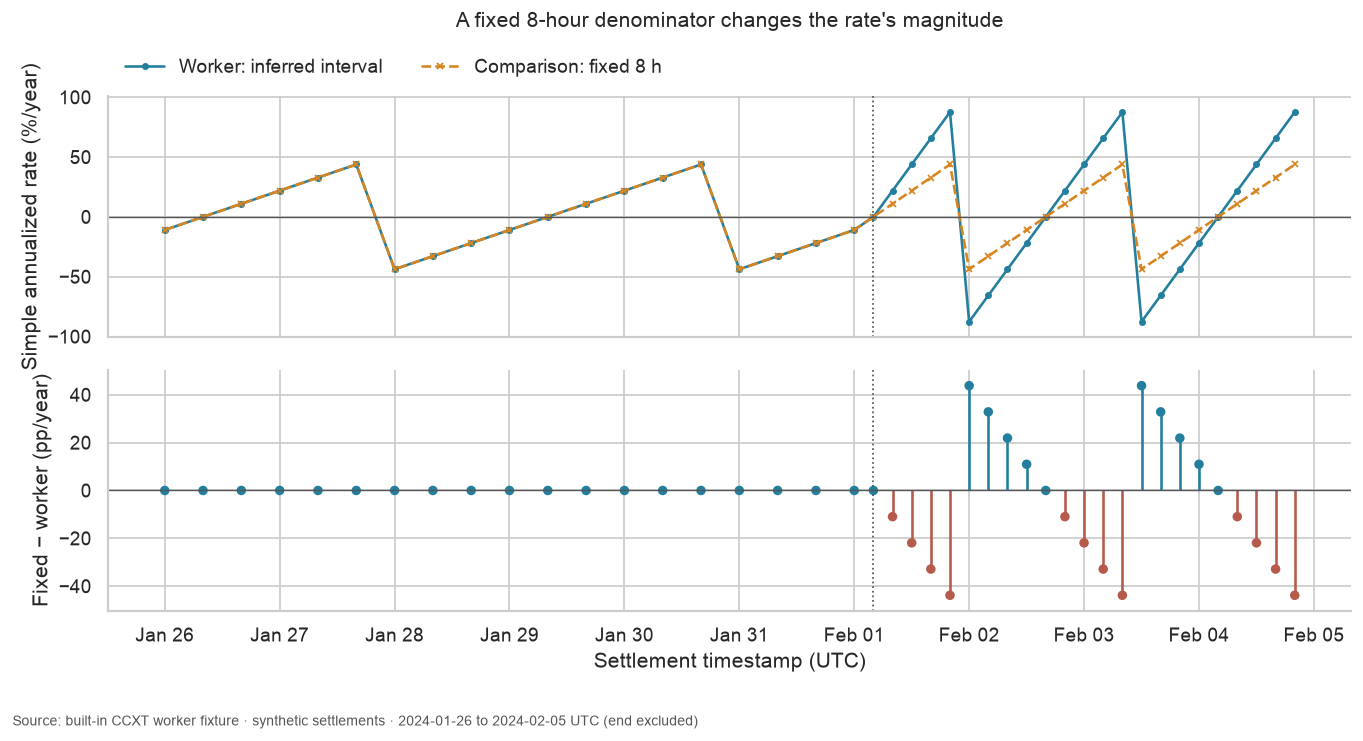

In [15]:
display(impact)
assert np.allclose(annualized.worker_annual_pct,annualized.recomputed_annual_pct,rtol=1e-12,atol=1e-12)
nonzero=annualized.funding_rate.ne(0)
assert np.allclose(annualized.loc[nonzero,"fixed_annual_pct"]/annualized.loc[nonzero,"worker_annual_pct"],annualized.loc[nonzero,"interval_hours"]/ASSUMED_HOURS)
assert np.allclose(annualized.loc[~nonzero,["worker_annual_pct","fixed_annual_pct"]],0)
changed=int(impact.changed_rates.sum());largest=float(impact.max_absolute_difference_pp.max())
prose(f"With a fixed **{ASSUMED_HOURS}-hour** assumption, **{changed} of {len(annualized)} settlement conversions** change. "
      f"The largest absolute discrepancy is **{largest:.2f} percentage points per year**. "
      "The last column expresses a magnitude ratio: below one understates both positive and negative magnitudes; above one overstates them. "
      "The SQL recomputation agrees with the worker's annualized value for every row.")
fig,axes=plt.subplots(2,1,figsize=(11,6.2),sharex=True)
axes[0].plot(annualized.ts,annualized.worker_annual_pct,color="#247f9e",marker="o",markersize=3,label="Worker: inferred interval")
axes[0].plot(annualized.ts,annualized.fixed_annual_pct,color="#d78520",linestyle="--",marker="x",markersize=4,label=f"Comparison: fixed {ASSUMED_HOURS} h")
scale=float((annualized.funding_rate.abs()*8760/4*100).max())*1.15
axes[0].set(ylabel="Simple annualized rate (%/year)",ylim=(-scale,scale),title=f"A fixed {ASSUMED_HOURS}-hour denominator changes the rate's magnitude")
axes[0].legend(loc="lower left",bbox_to_anchor=(0,1.01),ncol=2,frameon=False)
axes[0].set_title(f"A fixed {ASSUMED_HOURS}-hour denominator changes the rate's magnitude",pad=40)
axes[1].vlines(annualized.ts,0,annualized.difference_pp,color=np.where(annualized.difference_pp<0,"#b65b4c","#247f9e"))
axes[1].scatter(annualized.ts,annualized.difference_pp,c=np.where(annualized.difference_pp<0,"#b65b4c","#247f9e"),s=20)
axes[1].set(ylabel="Fixed − worker (pp/year)",ylim=(-scale/2,scale/2),xlabel="Settlement timestamp (UTC)")
for ax in axes:
 ax.axhline(0,color="#555555",linewidth=.8)
 for x in changes:ax.axvline(x,color="#555555",linestyle=":",linewidth=1)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"));finish(fig)

## One change to test

Change only **`ASSUMED_HOURS = 8` to `4`**, using the separate-output command in the [README](README.md). Confirm the source fingerprint, availability table and first chart stay identical. In the second chart, the four-hour segment should now agree while the eight-hour segment's nonzero magnitudes are overstated. Compare both the ratio column and signed difference; negative funding is not a missing value.

Restore **8** afterward. This controlled fixture proves the normalization behavior for its schedule, including a page continuation and interval transition. It does not establish current exchange availability, completeness of real historical data, trading costs or realizable returns. Real exchanges can restrict access, retain short histories or report missing timestamps; the worker's live read-only validation is documented separately.

In [16]:
con.execute("DETACH ccxt")
con.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Notebook setup and source](README.md)